In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import joblib

In [2]:
!pip install -U optuna seaborn pandas
import pandas as pd
import seaborn as sns
color_pal = sns.color_palette()

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 67.4 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.2
    Uninstalling pandas-2.2.2:
      Successfully uninstalled pandas-2.2.2
  Attempting uninstall: seaborn
    Found existing installation: seaborn 0.12.2
    Uninstalling seaborn-0.12.2:
      Successfully uninstalled seaborn-0.12.2
  Attempting uninstall: optuna
    Found existing installation: optuna 3.6.1
    Uninstalling optuna-3.6.1:
      Successfully uninstalled optuna-3.6.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-decision-forests 1.8.1 requires 

In [3]:
!pip install -U optuna
import optuna
print(optuna.__version__)

5.0.0


In [4]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/playground-series-s5e8/sample_submission.csv
/kaggle/input/playground-series-s5e8/train.csv
/kaggle/input/playground-series-s5e8/test.csv


In [5]:
np.random.seed(42)


In [6]:
#DataFrame with training data
train_df = pd.read_csv('/kaggle/input/playground-series-s5e8/train.csv')
#DataFrame with testing data
test_df = pd.read_csv('/kaggle/input/playground-series-s5e8/test.csv')

print(train_df.head(5))

   id  age          job  marital  education default  balance housing loan  \
0   0   42   technician  married  secondary      no        7      no   no   
1   1   38  blue-collar  married  secondary      no      514      no   no   
2   2   36  blue-collar  married  secondary      no      602     yes   no   
3   3   27      student   single  secondary      no       34     yes   no   
4   4   26   technician  married  secondary      no      889     yes   no   

    contact  day month  duration  campaign  pdays  previous poutcome  y  
0  cellular   25   aug       117         3     -1         0  unknown  0  
1   unknown   18   jun       185         1     -1         0  unknown  0  
2   unknown   14   may       111         2     -1         0  unknown  0  
3   unknown   28   may        10         2     -1         0  unknown  0  
4  cellular    3   feb       902         1     -1         0  unknown  1  


In [7]:
print(train_df.describe(include='all'))
print(train_df.info())

                   id            age         job  marital  education default  \
count   750000.000000  750000.000000      750000   750000     750000  750000   
unique            NaN            NaN          12        3          4       2   
top               NaN            NaN  management  married  secondary      no   
freq              NaN            NaN      175541   480759     401683  737151   
mean    374999.500000      40.926395         NaN      NaN        NaN     NaN   
std     216506.495284      10.098829         NaN      NaN        NaN     NaN   
min          0.000000      18.000000         NaN      NaN        NaN     NaN   
25%     187499.750000      33.000000         NaN      NaN        NaN     NaN   
50%     374999.500000      39.000000         NaN      NaN        NaN     NaN   
75%     562499.250000      48.000000         NaN      NaN        NaN     NaN   
max     749999.000000      95.000000         NaN      NaN        NaN     NaN   

              balance housing    loan  

In [8]:
print(test_df.describe(include='all'))
print(test_df.info())

                   id            age         job  marital  education default  \
count   250000.000000  250000.000000      250000   250000     250000  250000   
unique            NaN            NaN          12        3          4       2   
top               NaN            NaN  management  married  secondary      no   
freq              NaN            NaN       58636   160412     133724  245843   
mean    874999.500000      40.932332         NaN      NaN        NaN     NaN   
std      72168.927986      10.081613         NaN      NaN        NaN     NaN   
min     750000.000000      18.000000         NaN      NaN        NaN     NaN   
25%     812499.750000      33.000000         NaN      NaN        NaN     NaN   
50%     874999.500000      39.000000         NaN      NaN        NaN     NaN   
75%     937499.250000      48.000000         NaN      NaN        NaN     NaN   
max     999999.000000      95.000000         NaN      NaN        NaN     NaN   

              balance housing    loan  

In [9]:
print(f"job:       {train_df.job.unique()}")
print(f"marital:   {train_df.marital.unique()}")
print(f"education: {train_df.education.unique()}")
print(f"housing:   {train_df.housing.unique()}")
print(f"loan:      {train_df.loan.unique()}")
print(f"contact:   {train_df.contact.unique()}")
print(f"month:     {train_df.month.unique()}")
print(f"poutcome:  {train_df.poutcome.unique()}")
print(f"y:         {train_df.y.unique()}")

job:       ['technician' 'blue-collar' 'student' 'admin.' 'management' 'entrepreneur'
 'self-employed' 'unknown' 'services' 'retired' 'housemaid' 'unemployed']
marital:   ['married' 'single' 'divorced']
education: ['secondary' 'primary' 'tertiary' 'unknown']
housing:   ['no' 'yes']
loan:      ['no' 'yes']
contact:   ['cellular' 'unknown' 'telephone']
month:     ['aug' 'jun' 'may' 'feb' 'apr' 'nov' 'jul' 'jan' 'oct' 'mar' 'sep' 'dec']
poutcome:  ['unknown' 'other' 'failure' 'success']
y:         [0 1]


In [10]:
print(f"job:       {test_df.job.unique()}")
print(f"marital:   {test_df.marital.unique()}")
print(f"education: {test_df.education.unique()}")
print(f"housing:   {test_df.housing.unique()}")
print(f"loan:      {test_df.loan.unique()}")
print(f"contact:   {test_df.contact.unique()}")
print(f"month:     {test_df.month.unique()}")
print(f"poutcome:  {test_df.poutcome.unique()}")

job:       ['blue-collar' 'management' 'self-employed' 'technician' 'services'
 'retired' 'entrepreneur' 'admin.' 'housemaid' 'unemployed' 'student'
 'unknown']
marital:   ['married' 'single' 'divorced']
education: ['secondary' 'tertiary' 'primary' 'unknown']
housing:   ['yes' 'no']
loan:      ['no' 'yes']
contact:   ['unknown' 'cellular' 'telephone']
month:     ['may' 'apr' 'jul' 'jan' 'feb' 'aug' 'nov' 'jun' 'sep' 'oct' 'mar' 'dec']
poutcome:  ['unknown' 'other' 'failure' 'success']


# Data analysis

### Age

In [11]:
len(train_df['age'].unique())

78

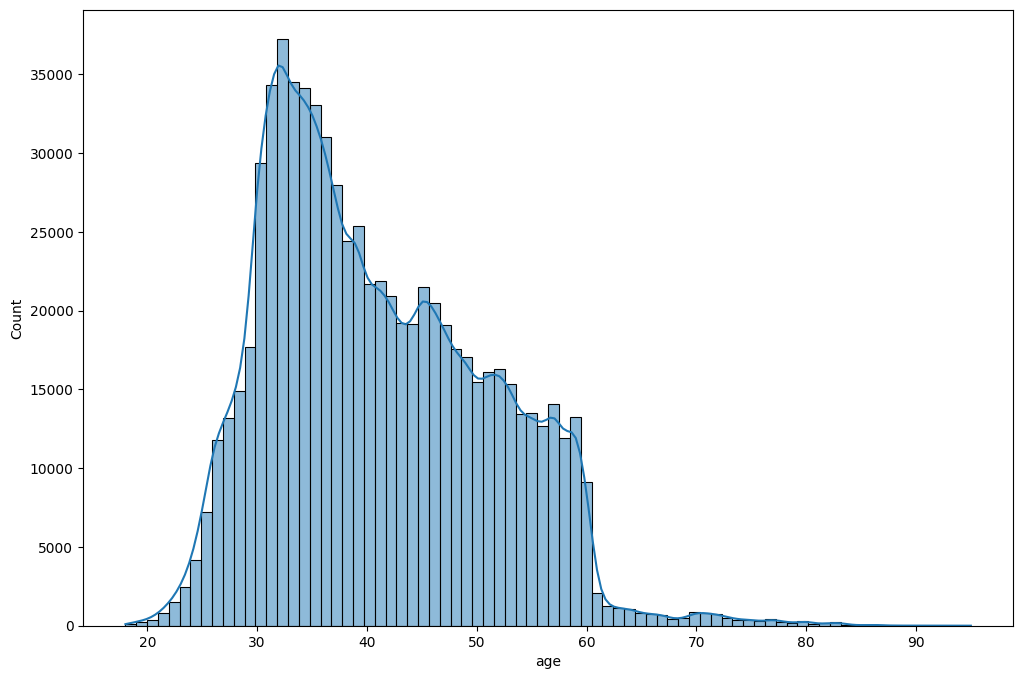

In [12]:

plt.figure(figsize=(12,8))
sns.histplot(data=train_df,
             x='age',
             color=color_pal[0],
             kde=True,
             bins=78
            )
plt.show()

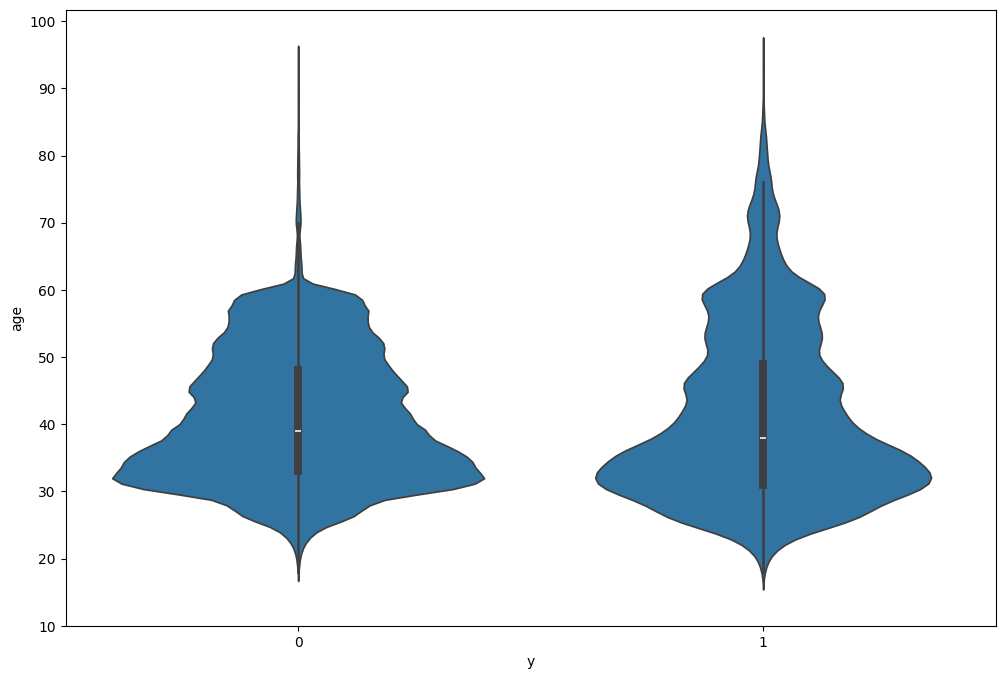

In [13]:
plt.figure(figsize=(12,8))
sns.violinplot(x='y', y='age', data=train_df).set_yticks(np.arange(10, 101, 10))

plt.show()


### Balance

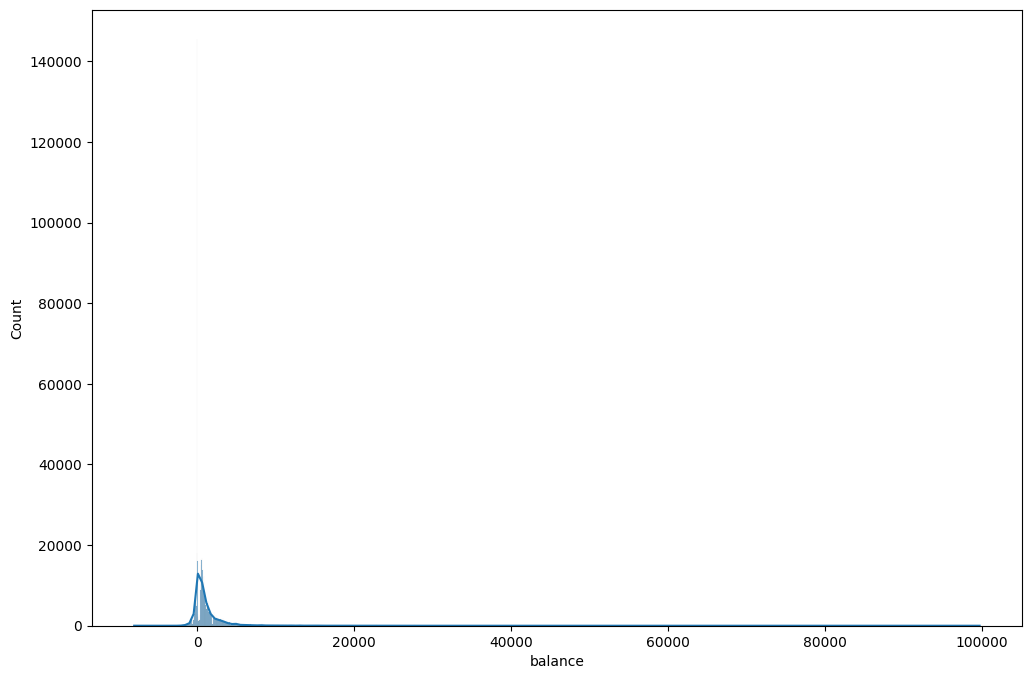

In [14]:
plt.figure(figsize=(12,8))
sns.histplot(data=train_df,
             x='balance',
             color=color_pal[0],
             kde=True)
plt.show()

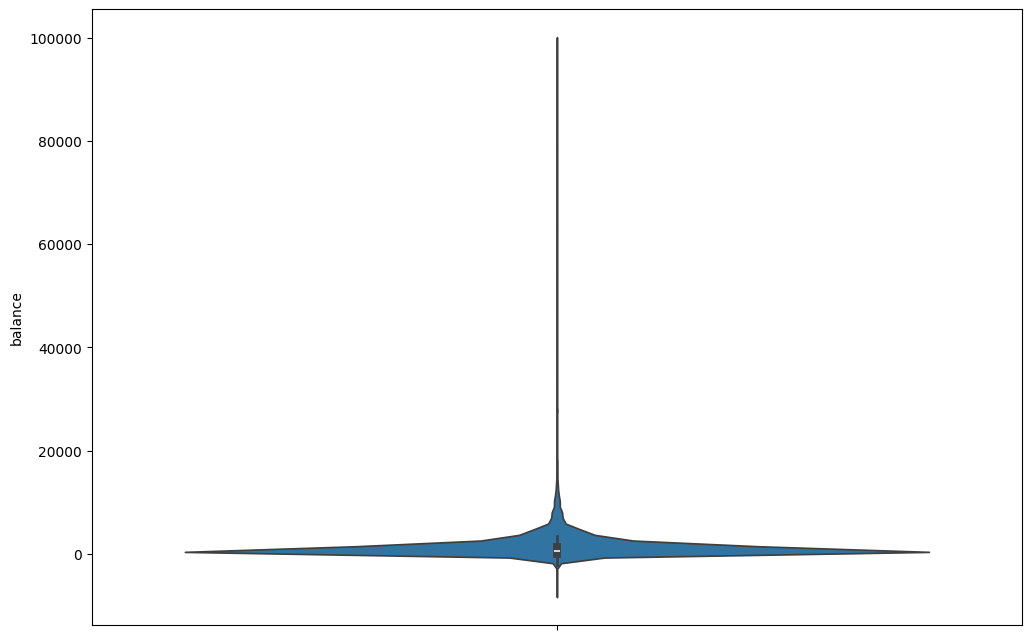

In [15]:
plt.figure(figsize=(12,8))
sns.violinplot( y='balance', data=train_df)
plt.show()

In [16]:
print(train_df.balance.nsmallest(10))
print(train_df.balance.nlargest(10))

18232    -8019
20822    -8019
47459    -8019
55214    -8019
55411    -8019
64574    -8019
99349    -8019
110354   -8019
120322   -8019
126457   -8019
Name: balance, dtype: int64
453989    99717
213252    99218
464263    98942
49547     98418
236770    98418
8578      98417
10392     98417
10440     98417
30594     98417
35381     98417
Name: balance, dtype: int64


### Day

In [17]:
len(train_df['day'].unique())

31

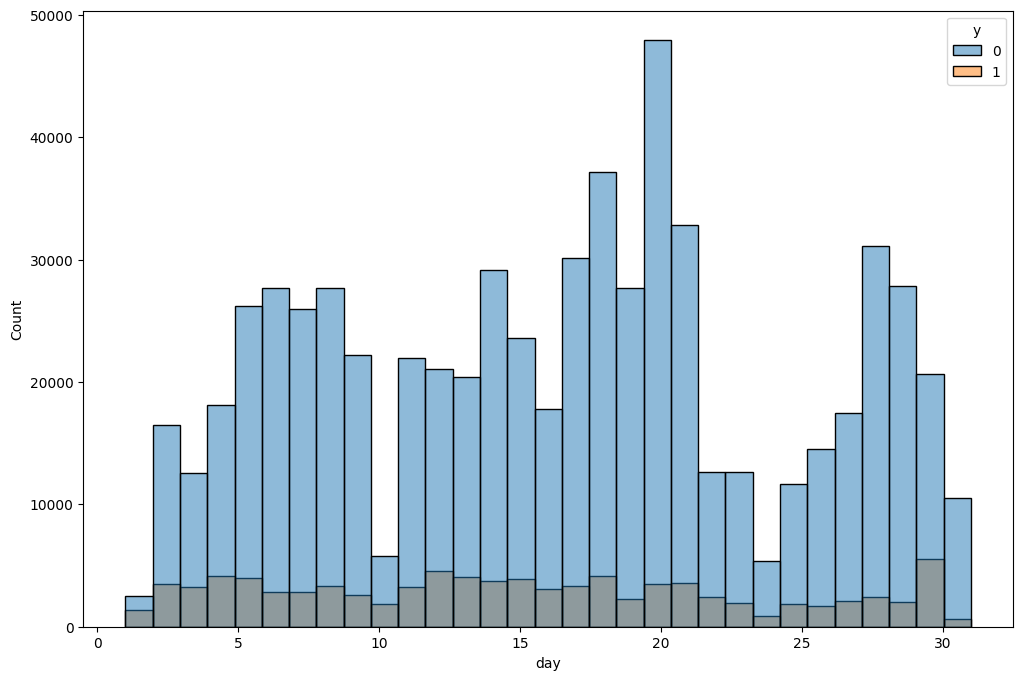

In [18]:
plt.figure(figsize=(12,8))
sns.histplot(data=train_df,
             hue='y',
             x='day',
             bins=31)
plt.show()

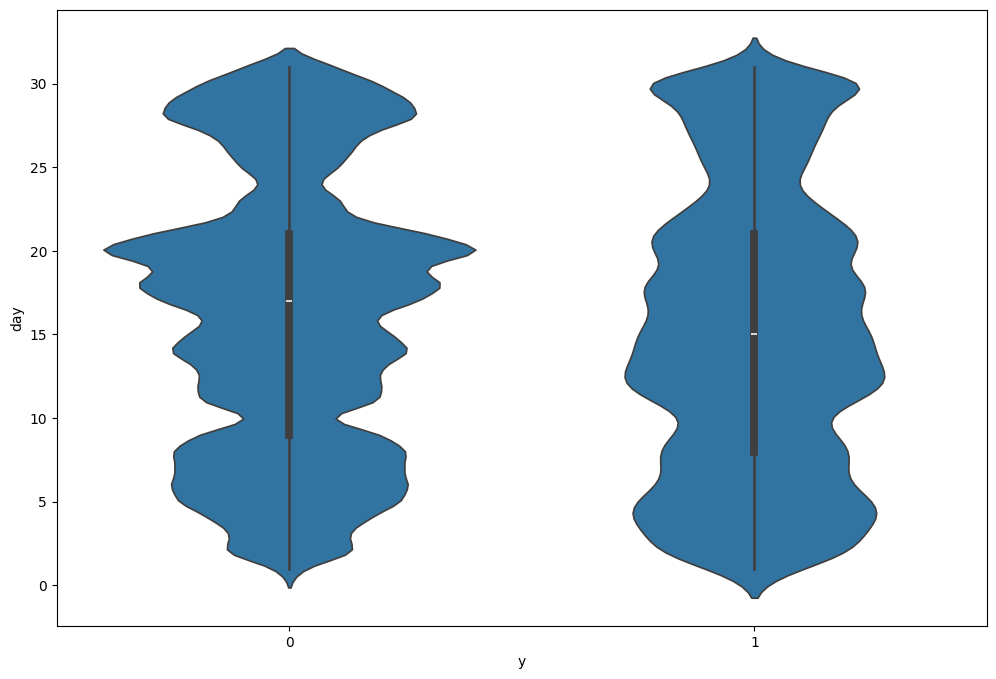

In [19]:
plt.figure(figsize=(12,8))
sns.violinplot( x='y', y='day', data=train_df)
plt.show()

### Duration

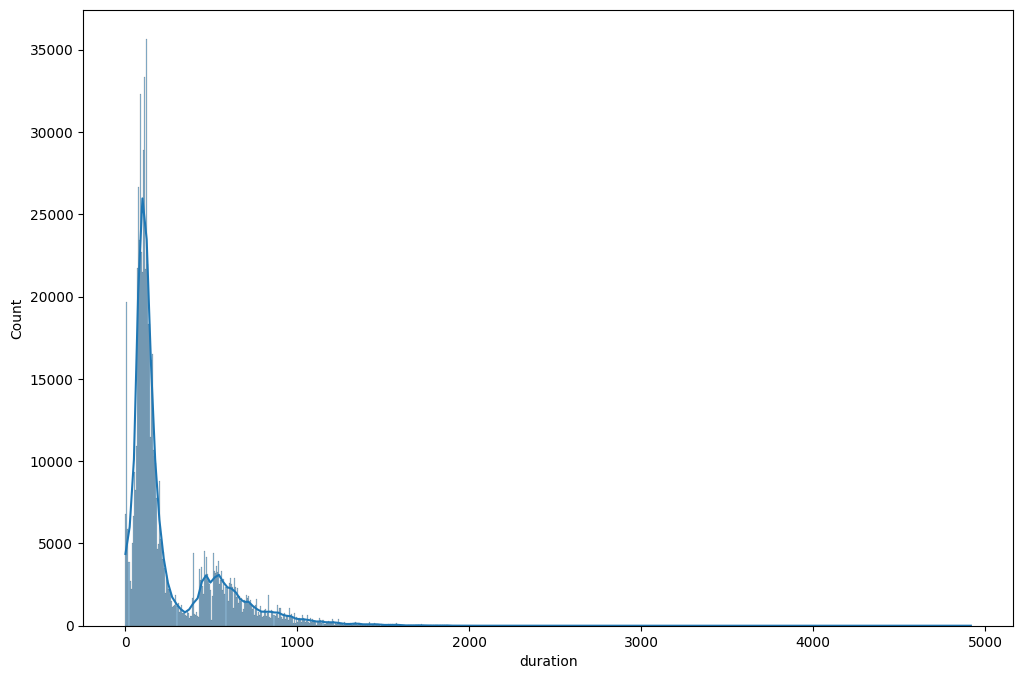

In [20]:
plt.figure(figsize=(12,8))
sns.histplot(data=train_df,
             x='duration',
             color=color_pal[0],
             kde=True)
plt.show()

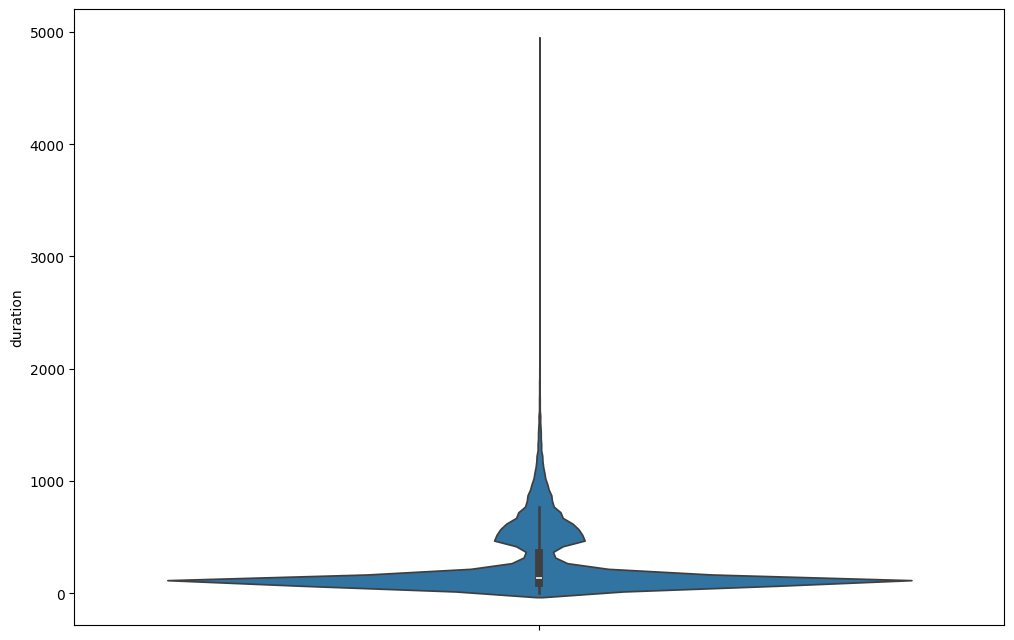

In [21]:
plt.figure(figsize=(12,8))
sns.violinplot( y='duration', data=train_df)
plt.show()

In [22]:
print(train_df.duration.nsmallest(10))
print(train_df.duration.nlargest(10))

47731     1
269221    1
298199    1
575563    1
648938    1
672102    1
490497    3
7591      4
9859      4
10642     4
Name: duration, dtype: int64
739177    4918
477980    4916
595734    4916
113334    4914
264264    4914
74126     4912
583357    4903
32085     4860
291128    4854
644556    4825
Name: duration, dtype: int64


### Campaign

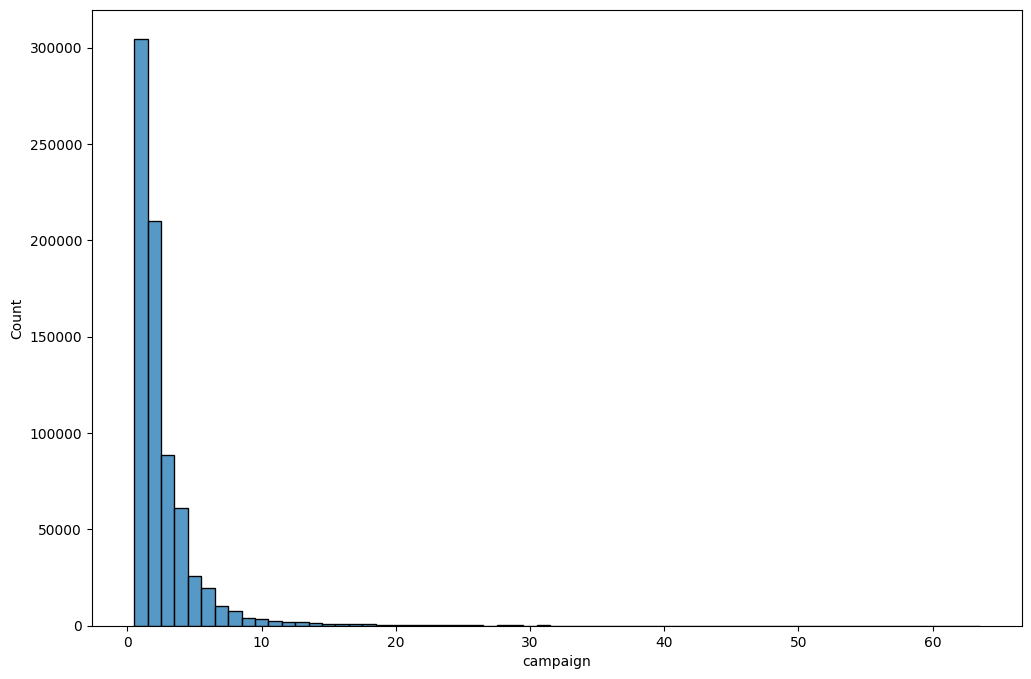

In [23]:
plt.figure(figsize=(12,8))
sns.histplot(data=train_df,
             x='campaign',
             discrete=True
            )
plt.show()

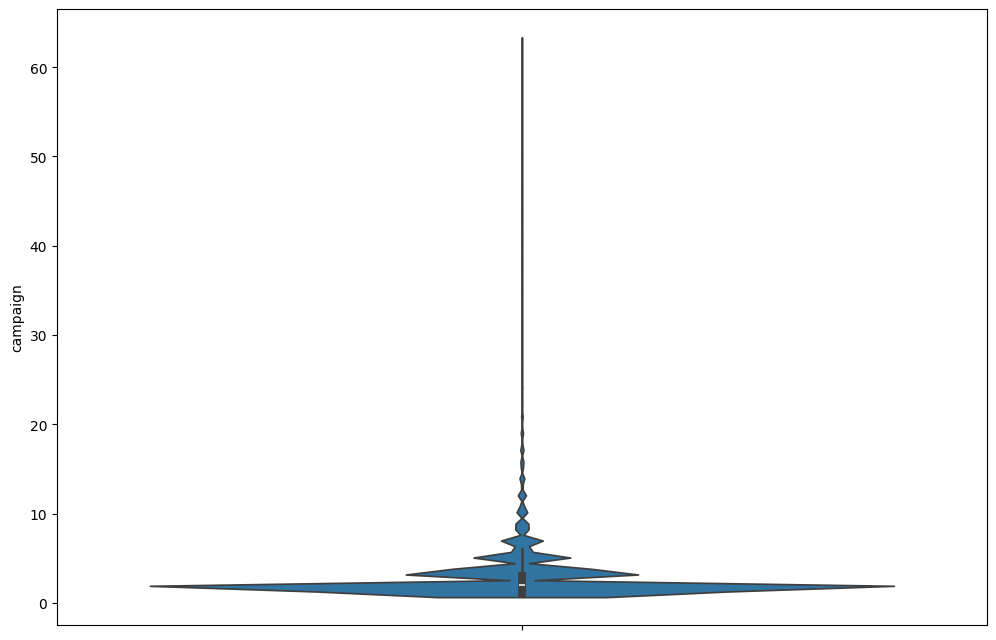

In [24]:
plt.figure(figsize=(12,8))
sns.violinplot( y='campaign', data=train_df)
plt.show()

In [25]:
print(train_df.campaign.nsmallest(10))
print(train_df.campaign.nlargest(10))

1     1
4     1
6     1
8     1
9     1
10    1
12    1
18    1
22    1
23    1
Name: campaign, dtype: int64
22290     63
215059    58
171760    55
27970     51
34662     51
70824     51
115060    51
282664    51
588424    51
695815    51
Name: campaign, dtype: int64


### Pdays

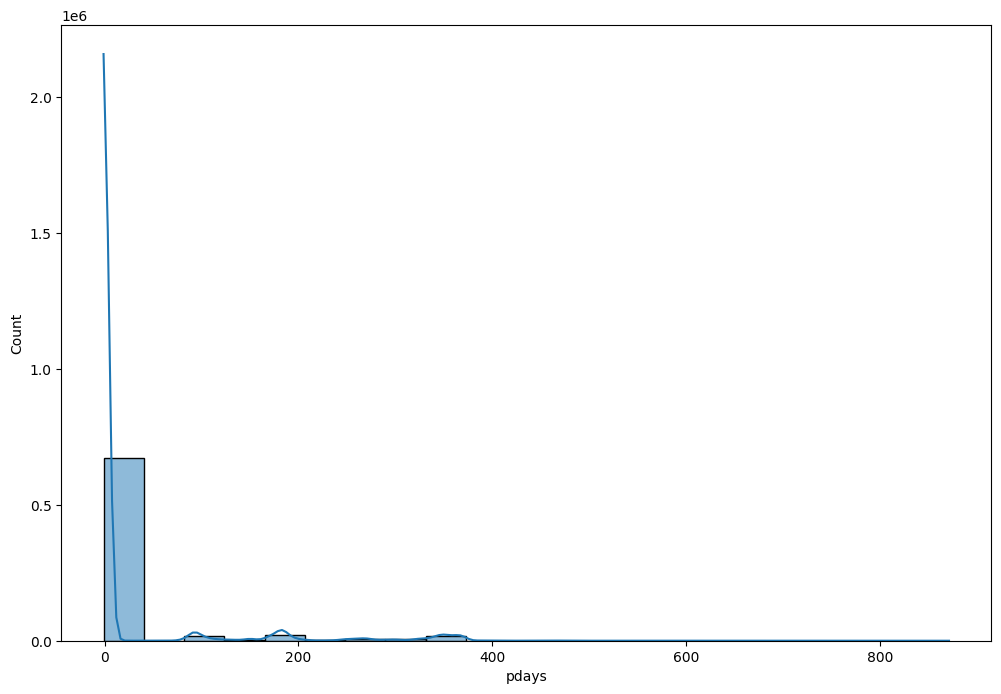

In [26]:
plt.figure(figsize=(12,8))
sns.histplot(data=train_df,
             x='pdays',
             color=color_pal[0],
             kde=True)
plt.show()

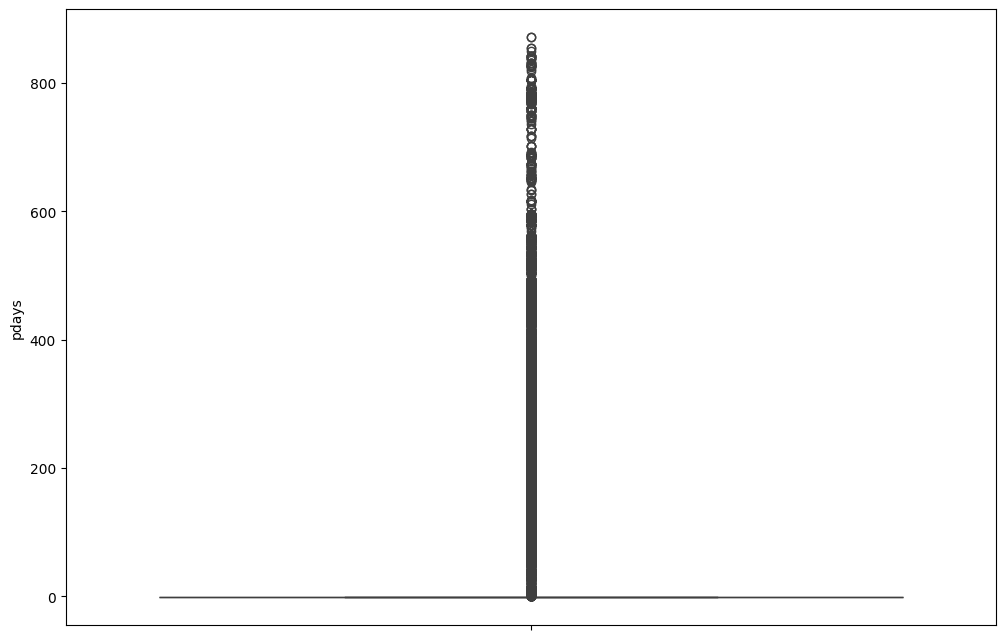

In [27]:
plt.figure(figsize=(12,8))
sns.boxplot( y='pdays', data=train_df)
plt.show()

In [28]:
print(train_df.pdays.nsmallest(10))
print(train_df.pdays.nlargest(10))

0   -1
1   -1
2   -1
3   -1
4   -1
5   -1
6   -1
7   -1
8   -1
9   -1
Name: pdays, dtype: int64
491713    871
647046    871
53984     854
552029    854
20525     850
11535     842
140895    842
227464    842
423424    842
438855    842
Name: pdays, dtype: int64


### Previous

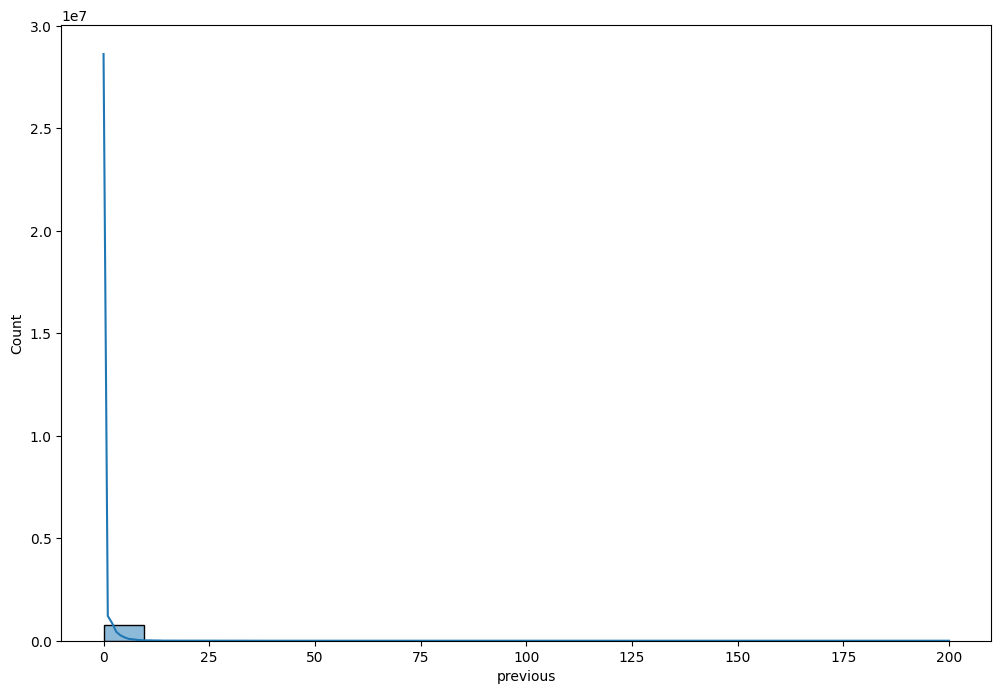

In [29]:
plt.figure(figsize=(12,8))
sns.histplot(data=train_df,
             x='previous',
             color=color_pal[0],
             kde=True)
plt.show()

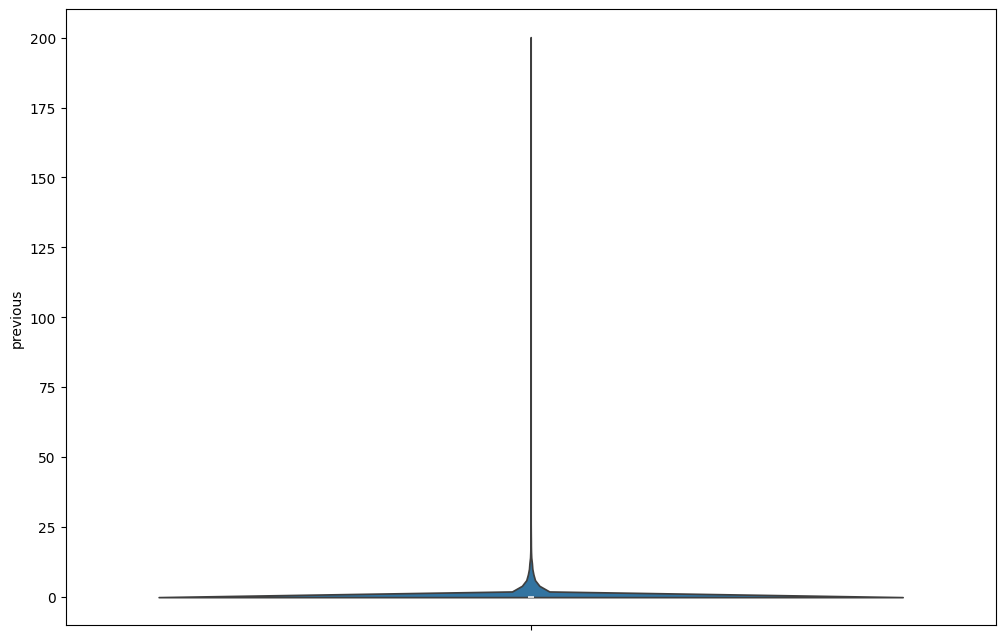

In [30]:
plt.figure(figsize=(12,8))
sns.violinplot( y='previous', data=train_df)
plt.show()

In [31]:
print(train_df.previous.nsmallest(10))
print(train_df.previous.nlargest(10))

0    0
1    0
2    0
3    0
4    0
5    0
6    0
7    0
8    0
9    0
Name: previous, dtype: int64
537358    200
676977     58
15984      55
634638     55
75832      51
336079     51
350746     51
554809     51
602770     48
437224     47
Name: previous, dtype: int64


In [32]:
train_df[train_df['previous'] == 200]

,id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
537358,537358,27,technician,single,tertiary,no,0,no,no,cellular,17,sep,7,1,100,200,other,0


In [33]:
#Quitar datos nulos 
# calcular el número de datos nulos por columna
missing_values_count = train_df.isna().sum()
print(missing_values_count)

id           0
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [34]:
train_df['previous']=train_df['previous'].replace(200,np.nan)

In [35]:
train_df=train_df.dropna()

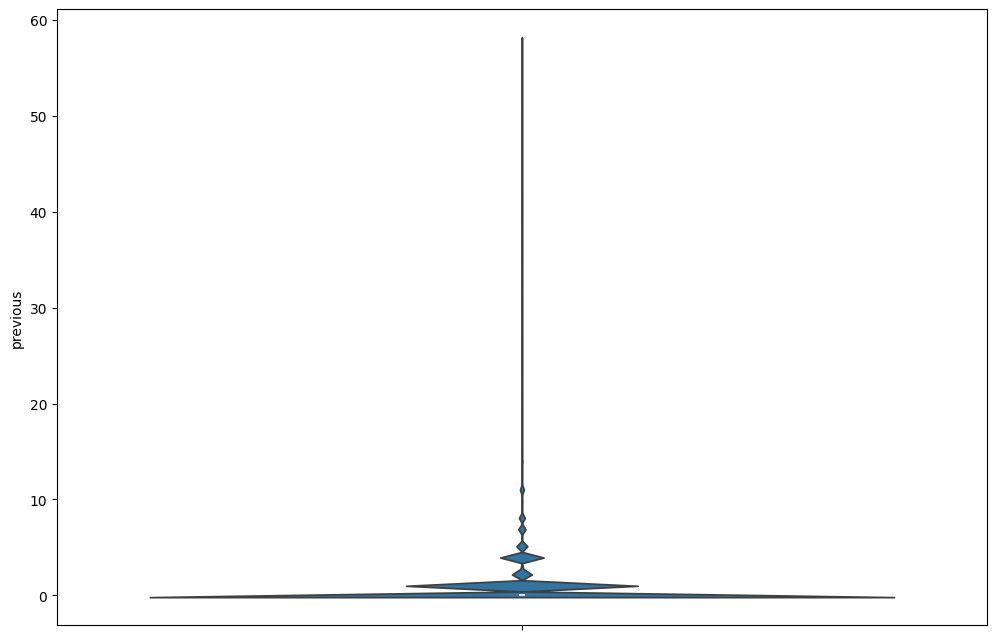

In [36]:
plt.figure(figsize=(12,8))
sns.violinplot( y='previous', data=train_df)
plt.show()

In [37]:
duplicated_values_count = train_df.duplicated().sum()
print(duplicated_values_count)

0


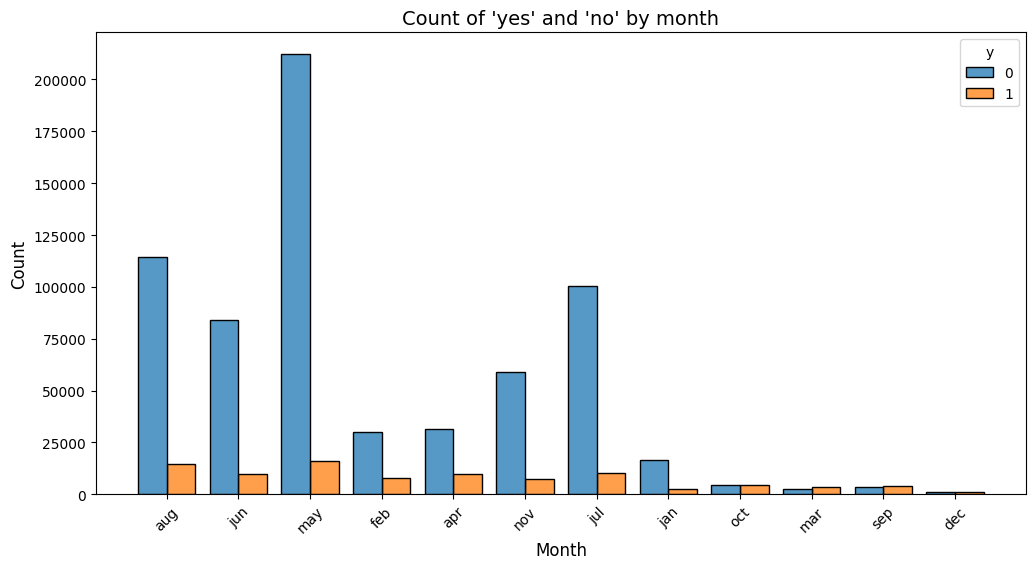

In [38]:
plt.figure(figsize=(12,6))

ax = sns.histplot(
    data=train_df,
    x="month",
    hue="y",   
    multiple="dodge", # not stacked bars
    shrink=0.8,       # bars width
    edgecolor="black", # bars edge
    legend=True
)


plt.title("Count of 'yes' and 'no' by month", fontsize=14)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xticks(rotation=45)  

plt.show()

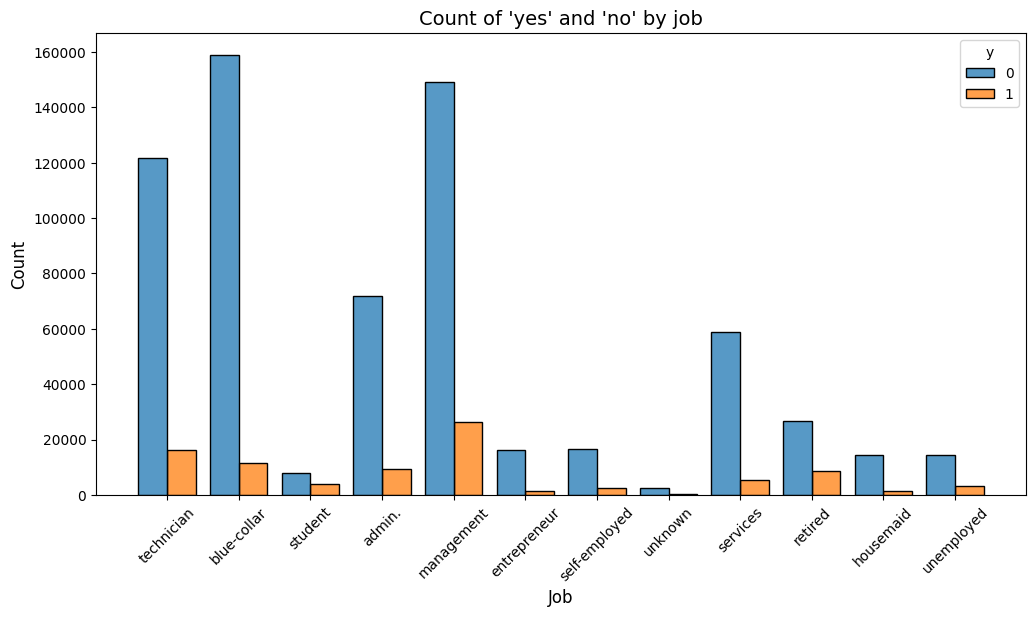

In [39]:
plt.figure(figsize=(12,6))

ax = sns.histplot(
    data=train_df,
    x="job",         
    hue="y",          
    multiple="dodge",
    shrink=0.8,     
    edgecolor="black", 
    legend=True
)


plt.title("Count of 'yes' and 'no' by job", fontsize=14)
plt.xlabel("Job", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xticks(rotation=45) 

plt.show()

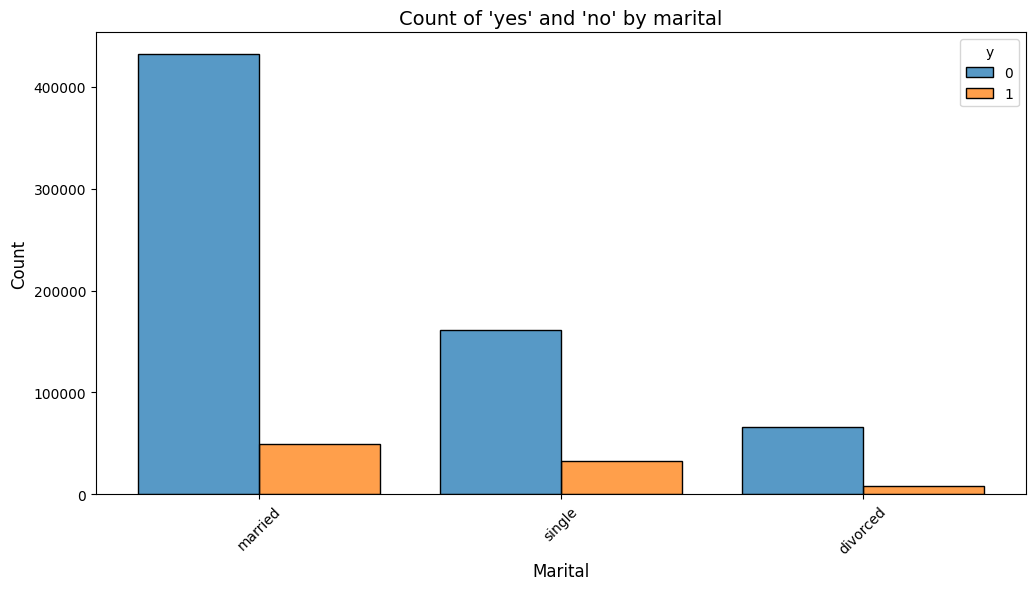

In [40]:
plt.figure(figsize=(12,6))

ax = sns.histplot(
    data=train_df,
    x="marital",         
    hue="y",          
    multiple="dodge", 
    shrink=0.8,       
    edgecolor="black",
    legend=True
)


plt.title("Count of 'yes' and 'no' by marital", fontsize=14)
plt.xlabel("Marital", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xticks(rotation=45)  

plt.show()

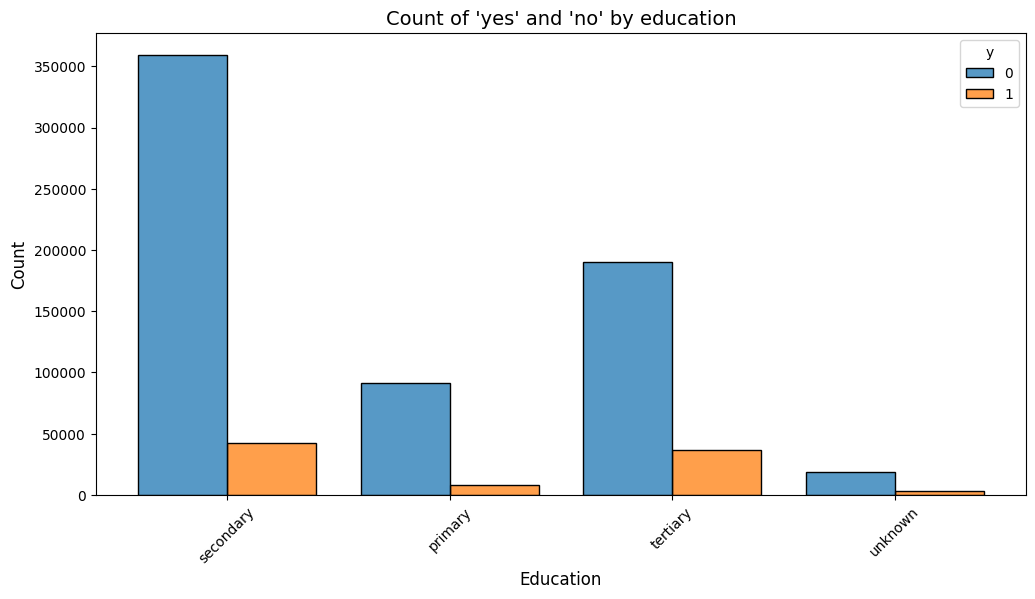

In [41]:
plt.figure(figsize=(12,6))

ax = sns.histplot(
    data=train_df,
    x="education",          
    hue="y",         
    multiple="dodge", 
    shrink=0.8,       
    edgecolor="black",
    legend=True
)


plt.title("Count of 'yes' and 'no' by education", fontsize=14)
plt.xlabel("Education", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xticks(rotation=45)  

plt.show()

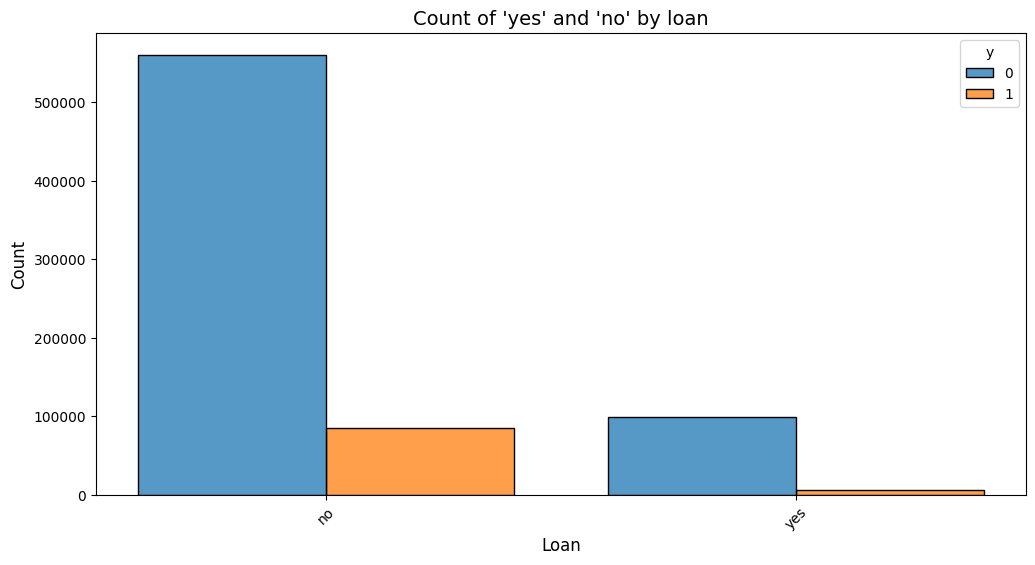

In [42]:
plt.figure(figsize=(12,6))

ax = sns.histplot(
    data=train_df,
    x="loan",          
    hue="y",          
    multiple="dodge",
    shrink=0.8,     
    edgecolor="black",
    legend=True
)


plt.title("Count of 'yes' and 'no' by loan", fontsize=14)
plt.xlabel("Loan", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xticks(rotation=45)  

plt.show()

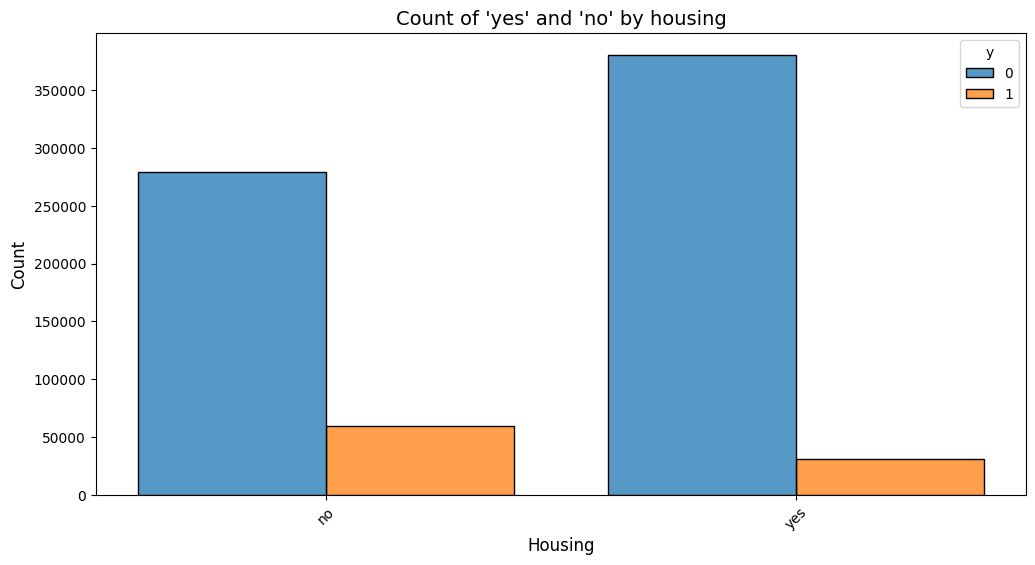

In [43]:
plt.figure(figsize=(12,6))

ax = sns.histplot(
    data=train_df,
    x="housing",          
    hue="y",          
    multiple="dodge", 
    shrink=0.8,      
    edgecolor="black", 
    legend=True
)


plt.title("Count of 'yes' and 'no' by housing", fontsize=14)
plt.xlabel("Housing", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xticks(rotation=45)  

plt.show()

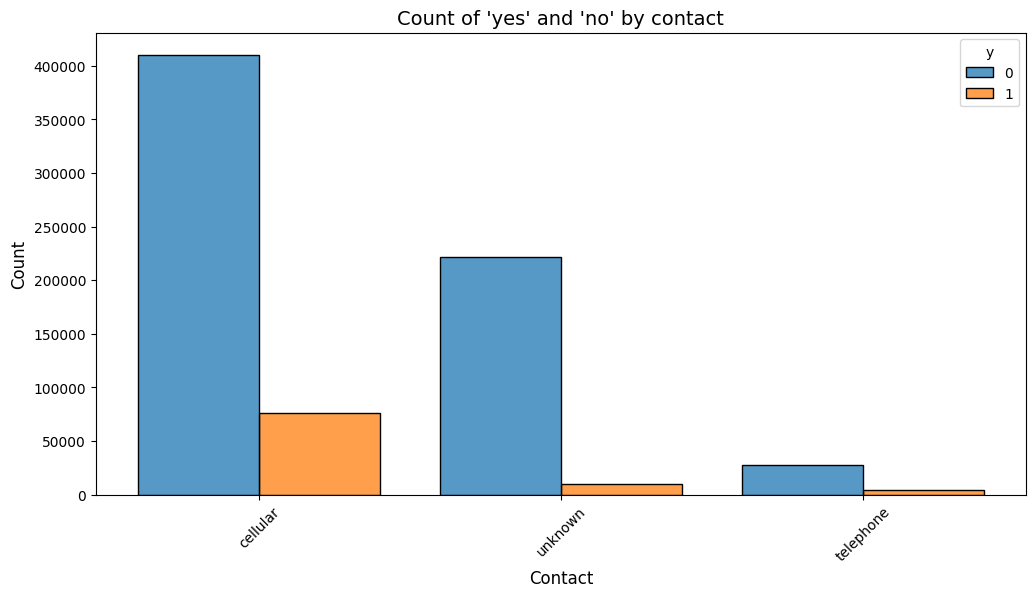

In [44]:
plt.figure(figsize=(12,6))

ax = sns.histplot(
    data=train_df,
    x="contact",          
    hue="y",          
    multiple="dodge", 
    shrink=0.8,       
    edgecolor="black", 
    legend=True
)


plt.title("Count of 'yes' and 'no' by contact", fontsize=14)
plt.xlabel("Contact", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xticks(rotation=45)  

plt.show()

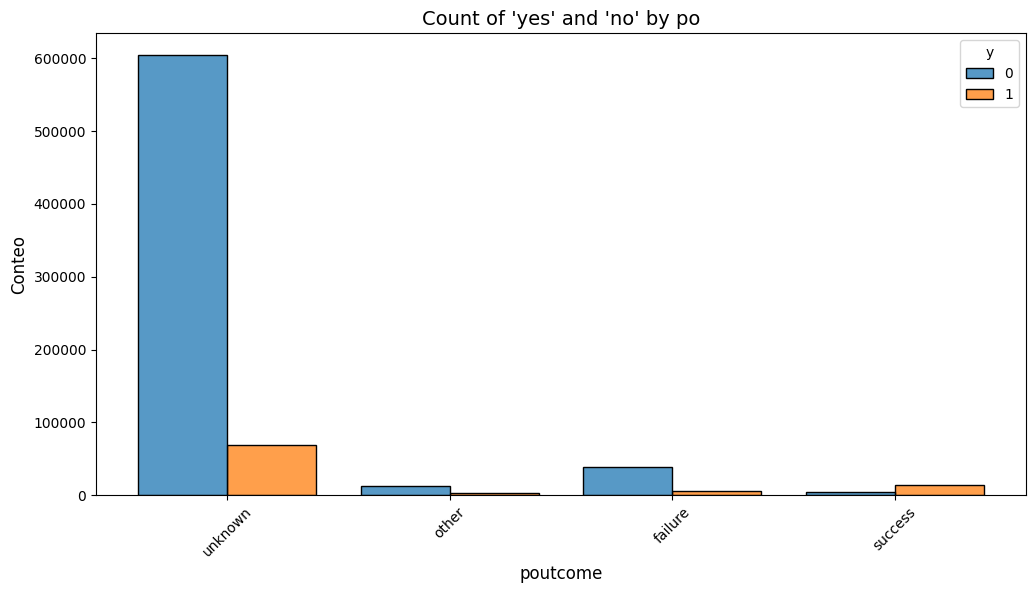

In [45]:
plt.figure(figsize=(12,6))

ax = sns.histplot(
    data=train_df,
    x="poutcome",          
    hue="y",         
    multiple="dodge", 
    shrink=0.8,     
    edgecolor="black", 
    legend=True
)


plt.title("Count of 'yes' and 'no' by po", fontsize=14)
plt.xlabel("poutcome", fontsize=12)
plt.ylabel("Conteo", fontsize=12)
plt.xticks(rotation=45)  

plt.show()

# Transformation

In [46]:
# Transformation of the categorical variable month to a numerical variable
months_to_number = {
    'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4,
    'may': 5, 'jun': 6, 'jul': 7, 'aug': 8,
    'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12
}

train_df['month']=train_df['month'].replace(months_to_number).astype(int)
test_df['month']=test_df['month'].replace(months_to_number).astype(int)

# Mapping dictionary 
educational_level= {
    'secondary': 2, 'primary': 1, 'tertiary': 3, 'unknown': 0
}

train_df.education=train_df.education.replace(educational_level).astype(int)
test_df.education=test_df.education.replace(educational_level).astype(int)


train_df.loan=train_df.loan.replace({'yes':1, 'no':0})
test_df.loan=test_df.loan.replace({'yes':1, 'no':0})

train_df.housing=train_df.housing.replace({'yes':1, 'no':0})
test_df.housing=test_df.housing.replace({'yes':1, 'no':0})

/tmp/ipykernel_17/2874199905.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_df['month']=train_df['month'].replace(months_to_number).astype(int)
/tmp/ipykernel_17/2874199905.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test_df['month']=test_df['month'].replace(months_to_number).astype(int)
/tmp/ipykernel_17/2874199905.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-i

In [47]:
#pasar variable categóricas a numéricas con onehotimputer
train_df.dtypes

id             int64
age            int64
job           object
marital       object
education      int64
default       object
balance        int64
housing        int64
loan           int64
contact       object
day            int64
month          int64
duration       int64
campaign       int64
pdays          int64
previous     float64
poutcome      object
y              int64
dtype: object

In [48]:
s = (train_df.dtypes == 'object')
object_cols = list(s[s].index)
print("Variables categóricas:")
print(object_cols)

Variables categóricas:
['job', 'marital', 'default', 'contact', 'poutcome']


In [49]:
from sklearn.preprocessing import OneHotEncoder
OH_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
OH_cols_train = pd.DataFrame(OH_encoder.fit_transform(train_df[object_cols]))
OH_cols_test = pd.DataFrame(OH_encoder.fit_transform(test_df[object_cols]))

# Obtener los nombres de las nuevas columnas
new_columns = OH_encoder.get_feature_names_out(object_cols)
OH_cols_train.columns = new_columns
OH_cols_test.columns = new_columns

OH_cols_train.index = train_df.index
OH_cols_test.index = test_df.index

#Eliminar las variables categóricas del dataframe 
num_x_train = train_df.drop(object_cols, axis=1)
num_x_test = test_df.drop(object_cols, axis=1)

#Unir las nuevas variables numericas al dataframe anterior
OH_x_train = pd.concat([num_x_train, OH_cols_train], axis=1)
OH_x_test = pd.concat([num_x_test, OH_cols_test], axis=1)

#Convertir el nombre de las columnas en strings
OH_x_train.columns = OH_x_train.columns.astype(str)
OH_x_test.columns = OH_x_test.columns.astype(str)


In [50]:
OH_x_train.dtypes

id                     int64
age                    int64
education              int64
balance                int64
housing                int64
loan                   int64
day                    int64
month                  int64
duration               int64
campaign               int64
pdays                  int64
previous             float64
y                      int64
job_admin.           float64
job_blue-collar      float64
job_entrepreneur     float64
job_housemaid        float64
job_management       float64
job_retired          float64
job_self-employed    float64
job_services         float64
job_student          float64
job_technician       float64
job_unemployed       float64
job_unknown          float64
marital_divorced     float64
marital_married      float64
marital_single       float64
default_no           float64
default_yes          float64
contact_cellular     float64
contact_telephone    float64
contact_unknown      float64
poutcome_failure     float64
poutcome_other

In [51]:
y_tr = OH_x_train['y']
x_tr = OH_x_train.drop(['y', 'id'], axis=1)
x_test = test_df.drop('id', axis=1)

In [52]:
from sklearn.model_selection import train_test_split

# Stratified hold-out: keeps the ~12% positive rate in both sets
x_train, x_val, y_train, y_val = train_test_split(
    x_tr, y_tr,
    test_size=0.2,
    stratify=y_tr,
    random_state=42,
)

In [53]:
import joblib
import optuna
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold, cross_val_score, learning_curve
from sklearn.metrics import (
    roc_auc_score, average_precision_score, log_loss,
    f1_score, precision_recall_curve, brier_score_loss
)
from optuna.pruners import MedianPruner

Output_directory = '/kaggle/working/'

# Save dataframes
x_train.to_parquet(f'{Output_directory}x_train.parquet')
x_test.to_parquet(f'{Output_directory}x_test.parquet')
y_train.to_frame(name='y').to_parquet(f'{Output_directory}y_train.parquet')

# Stratified CV: keeps the ~12% positive rate in every fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Pruner (use with trial.report(auc, step) inside the objective)
pruner = MedianPruner(n_startup_trials=8, n_warmup_steps=2, interval_steps=1, n_min_trials=8)

# Early stopping for the whole study (the metric is maximized, logic is the same)
def early_stopping(study, trial, patience=30, start_trial_number=0):
    trials_since_start = trial.number - start_trial_number
    if trials_since_start < patience:
        return
    best_trial_number = study.best_trial.number
    if best_trial_number < start_trial_number:
        trials_without_improvement = trials_since_start
    else:
        trials_without_improvement = trial.number - best_trial_number
    if trials_without_improvement >= patience:
        print(f"No improvement in the last {patience} trials. Stopping study.")
        study.stop()

sampler = optuna.samplers.TPESampler(seed=42)
# study = optuna.create_study(direction='maximize', sampler=sampler, pruner=pruner)

#####################################################################
# METRICS
#####################################################################

def cross_val(model, X, y, name=""):
    scores = cross_val_score(model, X, y, cv=skf, scoring='roc_auc', n_jobs=-1)
    print(f"--- {name}: Cross-validation (5 folds) ---")
    print(f"AUC per fold: {np.round(scores, 4)}")
    print(f"Mean: {scores.mean():.4f} | Std: {scores.std():.4f}")
    return {'cv_mean': scores.mean(), 'cv_std': scores.std()}

def cross_val_xgb(params, X, y, skf):
    scores = []
    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]

        model = xgb.XGBClassifier(
            **params,
            objective='binary:logistic',
            eval_metric='auc',
            early_stopping_rounds=30,
            random_state=42,
            n_jobs=-1,
        )
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)

        pred = model.predict_proba(X_va)[:, 1]  # probabilities, not classes
        auc = roc_auc_score(y_va, pred)
        scores.append(auc)
        print(f"Fold {fold + 1}: {auc:.4f}")

    print(f"CV mean: {np.mean(scores):.4f}")
    print(f"CV std: {np.std(scores):.4f}")
    return np.array(scores)

def plot_learning_curve(model, X, y, name=""):
    model_lc = xgb.XGBClassifier(**model.get_params())
    model_lc.set_params(early_stopping_rounds=None)  # no eval_set inside learning_curve

    train_sizes, train_scores, val_scores = learning_curve(
        model_lc, X, y, cv=skf, scoring='roc_auc',
        train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=-1
    )

    plt.figure(figsize=(10, 6))
    plt.plot(train_sizes, train_scores.mean(axis=1), label="Train AUC")
    plt.plot(train_sizes, val_scores.mean(axis=1), label="Validation AUC")
    plt.xlabel("Training samples")
    plt.ylabel("AUC")
    plt.title(f"Learning Curve - {name}")
    plt.legend()
    plt.show()

def evaluate_additional_metrics(y_true, y_prob, name=""):
    # Best F1 threshold (0.5 is rarely optimal with 12% positives)
    prec, rec, thr = precision_recall_curve(y_true, y_prob)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    best_idx = np.argmax(f1[:-1])
    best_thr = thr[best_idx]

    print(f"--- {name}: Additional metrics ---")
    print(f"AUC: {roc_auc_score(y_true, y_prob):.4f} | PR-AUC: {average_precision_score(y_true, y_prob):.4f}")
    print(f"Log loss: {log_loss(y_true, y_prob):.4f} | Brier: {brier_score_loss(y_true, y_prob):.4f}")
    print(f"Best F1: {f1[best_idx]:.4f} at threshold {best_thr:.3f}")
    print(f"Mean predicted prob: {np.mean(y_prob):.4f} | Real rate: {np.mean(y_true):.4f}")

def evaluate_gap(y_train, prob_train, y_val, prob_val, name=""):
    auc_train = roc_auc_score(y_train, prob_train)
    auc_val = roc_auc_score(y_val, prob_val)
    gap = auc_train - auc_val  # overfitting: train is expected to be higher
    gap_pct = gap / auc_train * 100

    print(f"--- {name}: Train vs Val ---")
    print(f"AUC train: {auc_train:.4f} | AUC val: {auc_val:.4f}")
    print(f"Gap: {gap:.4f} ({gap_pct:.2f}%)")
    return {'auc_train': auc_train, 'auc_val': auc_val, 'gap_pct': gap_pct}

In [54]:
##############################################################
# 1. XGBoost
##############################################################
from functools import partial
from xgboost import XGBClassifier

def objective_xgb(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 500, 1500),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 50),
        'gamma': trial.suggest_float('gamma', 1e-3, 5, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'colsample_bylevel': trial.suggest_float('colsample_bylevel', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1, 100.0, log=True),
        'random_state': 42,
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'n_jobs': -1,
    }

    fold_scores = []
    for fold_idx, (train_idx, val_idx) in enumerate(skf.split(x_train, y_train)):
        X_f_tr, X_f_va = x_train.iloc[train_idx], x_train.iloc[val_idx]
        y_f_tr, y_f_va = y_train.iloc[train_idx], y_train.iloc[val_idx]

        model = XGBClassifier(**param, early_stopping_rounds=30)
        model.fit(X_f_tr, y_f_tr, eval_set=[(X_f_va, y_f_va)], verbose=False)

        pred = model.predict_proba(X_f_va)[:, 1]  # probabilities for AUC
        auc = roc_auc_score(y_f_va, pred)
        fold_scores.append(auc)

        trial.report(np.mean(fold_scores), step=fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return np.mean(fold_scores)

# direction='maximize' because AUC is better when higher
study_xgb = optuna.create_study(sampler=sampler, direction='maximize', pruner=pruner)
study_xgb.optimize(objective_xgb, n_trials=150, callbacks=[partial(early_stopping, patience=20)])
print(f"XGBoost best parameters: {study_xgb.best_params}")

# Save the study
joblib.dump(study_xgb, f'{Output_directory}study_xgb.pkl')

# Load study
# study_xgb = joblib.load('/kaggle/input/datasets/davibaca/study-xgb/study_xgb.pkl')

[I 2026-10-29 13:00:16,587] A new study created in memory with name: no-name-660d02dc-80eb-4a0f-a0b4-97d0cb32d857
[I 2026-10-29 13:06:24,453] Trial 0 finished with value: 0.9675179340185315 and parameters: {'n_estimators': 874, 'learning_rate': 0.09237421878009823, 'max_depth': 7, 'min_child_weight': 30, 'gamma': 0.003776663327107336, 'subsample': 0.662397808134481, 'colsample_bytree': 0.5290418060840998, 'colsample_bylevel': 0.9330880728874675, 'reg_alpha': 0.2537815508265665, 'reg_lambda': 26.070247583707673}. Best is trial 0 with value: 0.9675179340185315.
[I 2026-10-29 13:10:02,834] Trial 1 finished with value: 0.9673721543296621 and parameters: {'n_estimators': 520, 'learning_rate': 0.09527257190058894, 'max_depth': 7, 'min_child_weight': 11, 'gamma': 0.004705059281907645, 'subsample': 0.6733618039413735, 'colsample_bytree': 0.6521211214797689, 'colsample_bylevel': 0.762378215816119, 'reg_alpha': 0.05342937261279776, 'reg_lambda': 3.8234752246751853}. Best is trial 0 with value: 0

No improvement in the last 20 trials. Stopping study.
XGBoost best parameters: {'n_estimators': 1405, 'learning_rate': 0.061843950560653366, 'max_depth': 8, 'min_child_weight': 30, 'gamma': 0.14142947016613555, 'subsample': 0.93229353703107, 'colsample_bytree': 0.5725530448751399, 'colsample_bylevel': 0.9896476337373644, 'reg_alpha': 0.007647413055367432, 'reg_lambda': 19.856079297853764}


['/kaggle/working/study_xgb.pkl']